# Bender's Decomposition Example from Linear Programming and Network Flows
## Example 7.2

In [10]:
import numpy as np
obj = np.array([-2, -1, -1, 1])
A = np.array([[1,0,1,0],[1,1,0,2],[1,0,0,0],[1,2,0,0],[0,0,-1,1],[0,0,2,1],[1,1,1,1],])
b = np.array([2,3,2,5,2,6,0])

### Key Insight:
Constraints (3), (4) only involve $x_1, x_2$; Constraints (5), (6) only involve $x_3, x_4$; therefore both constraint sets can be optimized with respect to one another independently. 

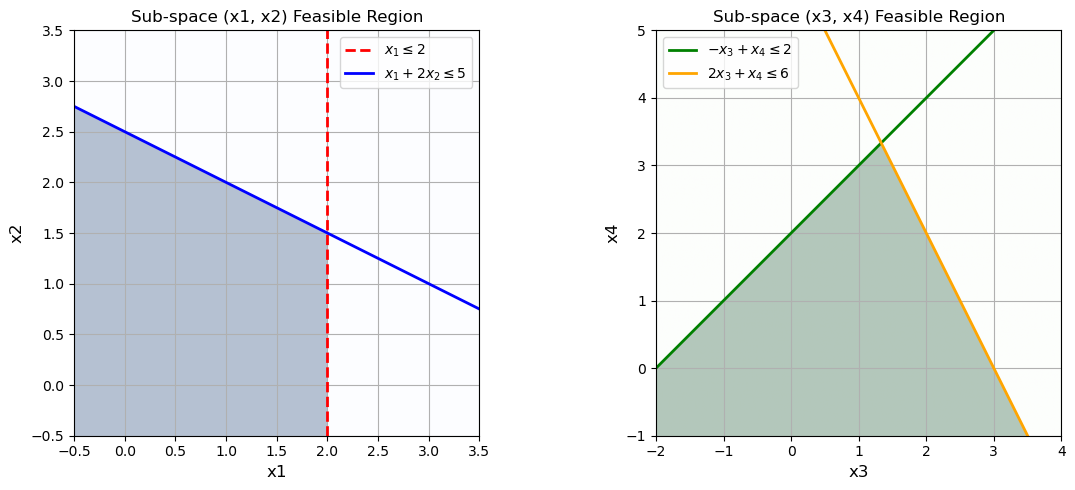

In [14]:
import matplotlib.pyplot as plt

x1_x2_rows = [i for i, row in enumerate(A) if row[2] == 0 and row[3] == 0 and (row[0] != 0 or row[1] != 0)]
x3_x4_rows = [i for i, row in enumerate(A) if row[0] == 0 and row[1] == 0 and (row[2] != 0 or row[3] != 0)]

# Plotting the updated feasible regions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: (x1, x2)
x1_vals = np.linspace(-1, 4, 400)
x2_vals = np.linspace(-1, 4, 400)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

region1 = (X1 <= 2) & (X1 + 2*X2 <= 5)
ax1 = axes[0]
ax1.imshow(region1.astype(int), extent=(-1, 4, -1, 4), origin='lower', cmap='Blues', alpha=0.3)
ax1.axvline(2, color='red', linestyle='--', label=r'$x_1 \leq 2$', linewidth=2)
ax1.plot(x1_vals, (5 - x1_vals)/2.0, color='blue', label=r'$x_1 + 2x_2 \leq 5$', linewidth=2)
ax1.set_xlim(-0.5, 3.5)
ax1.set_ylim(-0.5, 3.5)
ax1.set_xlabel('x1', fontsize=12)
ax1.set_ylabel('x2', fontsize=12)
ax1.set_title('Sub-space (x1, x2) Feasible Region', fontsize=12)
ax1.grid(True)
ax1.legend()

# Plot 2: (x3, x4)
x3_vals = np.linspace(-2, 5, 400)
x4_vals = np.linspace(-1, 5, 400)
X3, X4 = np.meshgrid(x3_vals, x4_vals)

region2 = (-X3 + X4 <= 2) & (2*X3 + X4 <= 6)
ax2 = axes[1]
ax2.imshow(region2.astype(int), extent=(-2, 5, -1, 5), origin='lower', cmap='Greens', alpha=0.3)
ax2.plot(x3_vals, 2 + x3_vals, color='green', label=r'$-x_3 + x_4 \leq 2$', linewidth=2)
ax2.plot(x3_vals, 6 - 2*x3_vals, color='orange', label=r'$2x_3 + x_4 \leq 6$', linewidth=2)
ax2.set_xlim(-2, 4)
ax2.set_ylim(-1, 5)
ax2.set_xlabel('x3', fontsize=12)
ax2.set_ylabel('x4', fontsize=12)
ax2.set_title('Sub-space (x3, x4) Feasible Region', fontsize=12)
ax2.grid(True)
ax2.legend()

plt.tight_layout()
#plt.savefig('updated_feasible_regions.png')
plt.show()


In [22]:
def create_tableau(A, b, c):
    m, n = A.shape
    I = np.eye(m)
    constraints = np.hstack([A, I, b.reshape(-1, 1)])
    obj_row = np.hstack([-c, np.zeros(m), [0]])
    tableau = np.vstack([constraints, obj_row])
    return tableau

In [23]:
# Given an initial solution x0
x0 = np.array([0, 0, 0, 0])
lhs = A @ x0
slacks = b - lhs

print("LHS at (0,0,0,0):", lhs)
print("Slacks (b - Ax):", slacks)
active_A_indices = np.where(slacks == 0)[0]
print("Active row indices of A (where A_i * x = b_i):", active_A_indices)
print("Active rows of A:", A[active_A_indices])

LHS at (0,0,0,0): [0 0 0 0 0 0 0]
Slacks (b - Ax): [2 3 2 5 2 6 0]
Active row indices of A (where A_i * x = b_i): [6]
Active rows of A: [[1 1 1 1]]


In [24]:
create_tableau(A, b, obj)

array([[ 1.,  0.,  1.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  2.],
       [ 1.,  1.,  0.,  2.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  3.],
       [ 1.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  2.],
       [ 1.,  2.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  5.],
       [ 0.,  0., -1.,  1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  2.],
       [ 0.,  0.,  2.,  1.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  6.],
       [ 1.,  1.,  1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.],
       [ 2.,  1.,  1., -1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]])